In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

In [ ]:

# Fungsi MAPE manual
def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

In [ ]:
# ----------- 1. Membaca dan mempersiapkan data --------------
from google.colab import files
uploaded = files.upload()

Saving Prophet Indeks.xlsx to Prophet Indeks.xlsx


In [ ]:
df = pd.read_excel("Prophet Indeks.xlsx")

In [ ]:
print(df.columns)

Index(['Waktu', 'Indeks'], dtype='object')


In [ ]:
df.rename(columns={'Waktu': 'ds', 'Indeks': 'y'}, inplace=True)


In [ ]:
# Asumsikan kolom 'tanggal' dan 'nilai'
df['ds'] = pd.to_datetime(df['ds'])
df = df.sort_values('ds')


In [ ]:
# ----------- 3. Membagi data training dan testing --------------
split_ratio = 0.8
split_index = int(len(df)*split_ratio)

train = df.iloc[:split_index]
test = df.iloc[split_index:]

In [ ]:
# Buat dataframe tanggal untuk prediksi test dan 15 bulan ke depan
last_date = df['ds'].max()
future_periods = (test.shape[0] + 15 * 30)  # kira-kira untuk test + 10 bulan (asumsi ~30 hari/bln)


In [ ]:
Prophet(growth='linear', changepoint_prior_scale=0.01,
        seasonality_mode='multiplicative',
    seasonality_prior_scale=5.0)


In [ ]:
from prophet import Prophet

model = Prophet(yearly_seasonality=True, daily_seasonality=False, weekly_seasonality=True)
model.fit(train)

DEBUG:cmdstanpy:input tempfile: /tmp/tmpgf7o1xnz/6hu99gqn.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpgf7o1xnz/5jvyk7d2.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=23414', 'data', 'file=/tmp/tmpgf7o1xnz/6hu99gqn.json', 'init=/tmp/tmpgf7o1xnz/5jvyk7d2.json', 'output', 'file=/tmp/tmpgf7o1xnz/prophet_modelj08ovmnb/prophet_model-20250627150516.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
15:05:16 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
15:05:16 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


In [ ]:

future = model.make_future_dataframe(periods=future_periods, freq='D')

In [ ]:
# ----------- 6. Prediksi --------------
forecast = model.predict(future)

In [ ]:
# Ambil hasil prediksi untuk test period saja (sama jumlahnya dengan test)
forecast_test = forecast[forecast['ds'].isin(test['ds'])]

In [ ]:
# ----------- 7. Evaluasi --------------
# Gabungkan berdasarkan ds
df_eval = test.merge(forecast[['ds', 'yhat']], on='ds', how='inner')

y_true = df_eval['y'].values
y_pred = df_eval['yhat'].values

mae = mean_absolute_error(y_true, y_pred)
mape = mean_absolute_percentage_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"MAE: {mae:.3f}")
print(f"MAPE: {mape:.3f}%")
print(f"RMSE: {rmse:.3f}")

MAE: 126.255
MAPE: 27.982%
RMSE: 149.538


In [ ]:
 #----------- 8. Ambil 10 bulan prediksi ke depan --------------
future_pred_start = test['ds'].max() + pd.Timedelta(days=1)
future_pred_end = future_pred_start + pd.DateOffset(months=10)

future_15_months = forecast[(forecast['ds'] >= future_pred_start) & (forecast['ds'] <= future_pred_end)]

In [ ]:
# Filter forecast hanya sampai data testing
forecast_visible = forecast[forecast['ds'] <= test['ds'].max()]


In [ ]:
# ----------- 8. Tampilkan hasil prediksi untuk data testing saja --------------
forecast_test = forecast[forecast['ds'].isin(test['ds'])]

# Gabungkan hasil prediksi dengan data aktual (optional, untuk evaluasi)
hasil_prediksi = test.merge(forecast_test[['ds', 'yhat', 'yhat_lower', 'yhat_upper']], on='ds', how='left')

# Tampilkan 10 baris pertama hasil prediksi
print("Hasil Prediksi Data Testing:")
print(hasil_prediksi.head(15))


Hasil Prediksi Data Testing:
           ds           y        yhat  yhat_lower  yhat_upper
0  2024-02-01  287.132502  322.849957  259.806449  386.080105
1  2024-03-01  219.834548  308.455316  244.366803  370.583967
2  2024-04-01  334.058519  294.581323  231.634314  360.580437
3  2024-05-01  355.971886  329.337961  268.396973  394.150274
4  2024-06-01  418.122586  386.980825  321.371410  449.057790
5  2024-07-01  402.350405  325.967265  259.169582  384.221497
6  2024-08-01  562.194428  340.734166  280.138043  405.331879
7  2024-09-01  442.230139  384.523341  318.447357  447.322848
8  2024-10-01  579.528741  352.880024  293.441441  415.981025
9  2024-11-01  501.231443  353.458287  292.793042  420.113442
10 2024-12-01  534.389066  338.204345  275.278648  397.679277
11 2025-01-01  338.068249  585.548489  524.319809  649.746944
12 2025-02-01  466.895445  375.827550  318.653937  436.555536
13 2025-03-01  608.549060  387.864930  324.436685  456.430772
14 2025-04-01  541.070648  354.229523  29

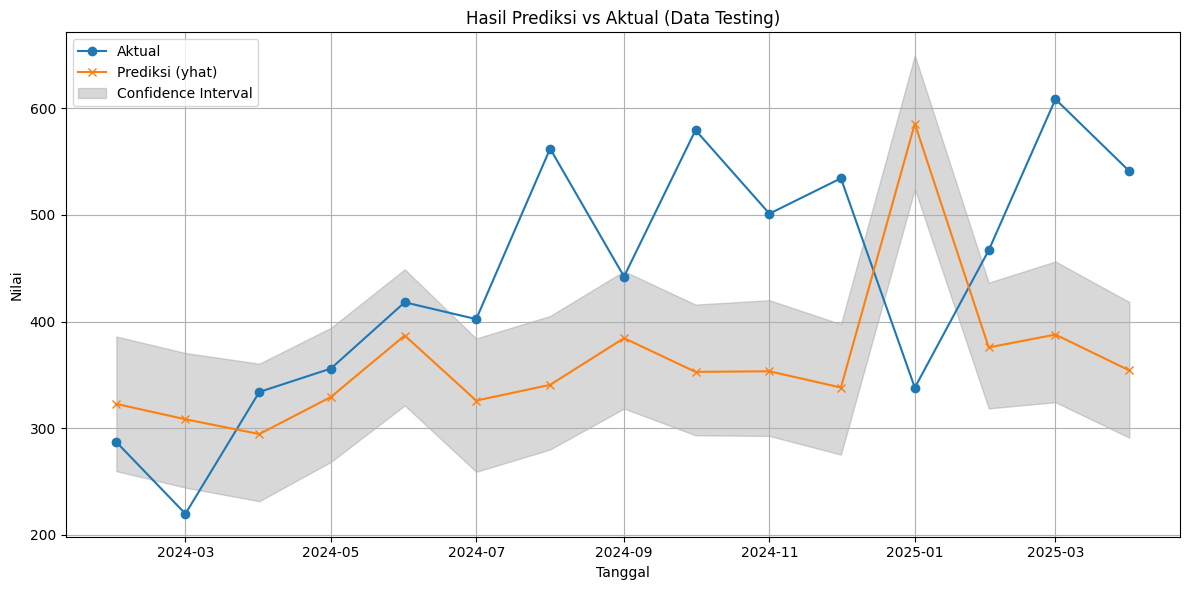

In [ ]:
# ----------- 9A. Visualisasi hasil prediksi vs aktual di data testing --------------
plt.figure(figsize=(12,6))
plt.plot(hasil_prediksi['ds'], hasil_prediksi['y'], label='Aktual', marker='o')
plt.plot(hasil_prediksi['ds'], hasil_prediksi['yhat'], label='Prediksi (yhat)', marker='x')
plt.fill_between(hasil_prediksi['ds'],
                 hasil_prediksi['yhat_lower'],
                 hasil_prediksi['yhat_upper'],
                 color='gray', alpha=0.3, label='Confidence Interval')

plt.xlabel('Tanggal')
plt.ylabel('Nilai')
plt.title('Hasil Prediksi vs Aktual (Data Testing)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from prophet import Prophet
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# 2. Latih model Prophet dengan seluruh data
model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
model.fit(df)

DEBUG:cmdstanpy:input tempfile: /tmp/tmpgf7o1xnz/_e4uzhx2.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpgf7o1xnz/8o27rvyf.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=9770', 'data', 'file=/tmp/tmpgf7o1xnz/_e4uzhx2.json', 'init=/tmp/tmpgf7o1xnz/8o27rvyf.json', 'output', 'file=/tmp/tmpgf7o1xnz/prophet_modeldd054g83/prophet_model-20250627150552.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
15:05:52 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
15:05:53 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


In [ ]:
# 3. Buat future dataframe untuk 10 bulan ke depan
future_11bulan = model.make_future_dataframe(periods=11, freq='M')  # freq M = bulanan


/usr/local/lib/python3.11/dist-packages/prophet/forecaster.py:1872: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(


In [ ]:
# 4. Prediksi ke depan
forecast_11bulan = model.predict(future_10bulan)


In [ ]:
# 5. Ambil hasil prediksi 10 bulan ke depan (setelah data historis terakhir)
last_date = df['ds'].max()
forecast_future = forecast_11bulan[forecast_11bulan['ds'] > last_date]


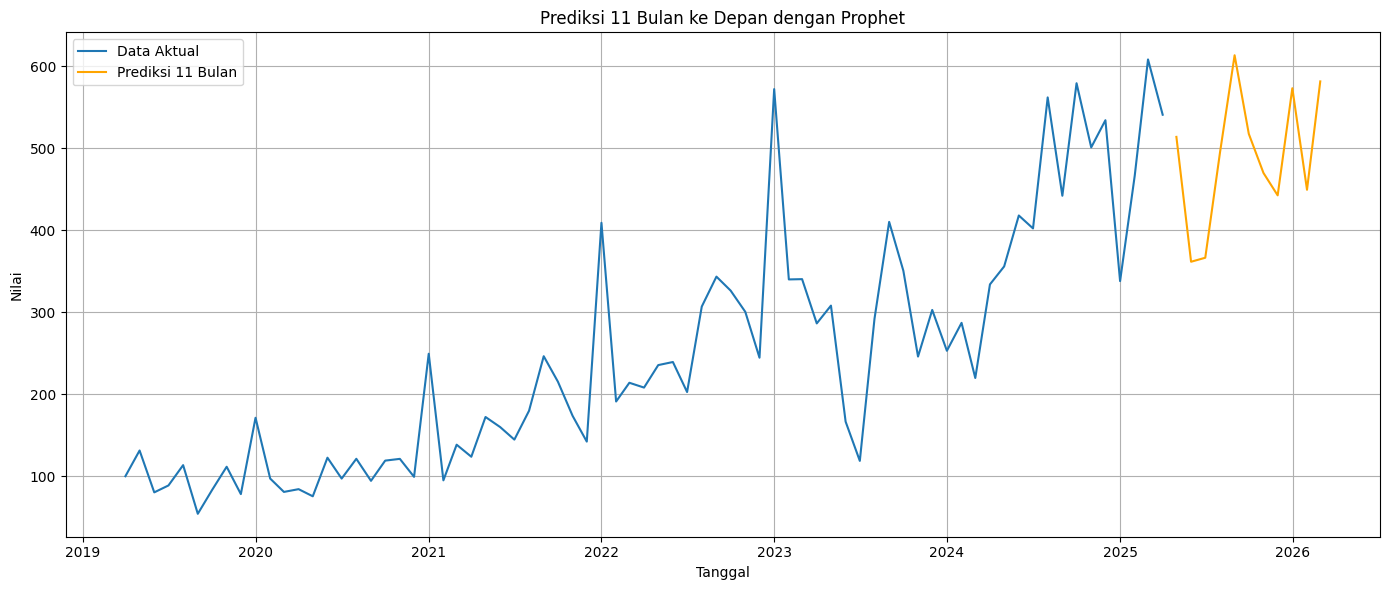

In [ ]:
# 6. Visualisasi
plt.figure(figsize=(14,6))
plt.plot(df['ds'], df['y'], label='Data Aktual')
plt.plot(forecast_future['ds'], forecast_future['yhat'], label='Prediksi 11 Bulan', color='orange')
plt.title('Prediksi 11 Bulan ke Depan dengan Prophet')
plt.xlabel('Tanggal')
plt.ylabel('Nilai')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# ----------- 7A. Tampilkan hasil prediksi untuk 10 bulan ke depan --------------
print("Hasil Prediksi 11 Bulan ke Depan:")
print(forecast_future[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head(11))  # Menampilkan 10 baris pertama

# ----------- 7B. Simpan hasil prediksi ke Excel/CSV --------------
forecast_future[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].to_csv("prediksi_11_bulan.csv", index=False)


Hasil Prediksi 11 Bulan ke Depan:
           ds        yhat  yhat_lower  yhat_upper
73 2025-04-30  514.041809  427.732197  605.605146
74 2025-05-31  361.694883  279.369782  452.441750
75 2025-06-30  366.565722  277.310807  457.091105
76 2025-07-31  494.501348  404.597262  587.436094
77 2025-08-31  613.637290  513.911035  701.083511
78 2025-09-30  517.725659  430.991016  607.027787
79 2025-10-31  470.006213  376.577273  555.234859
80 2025-11-30  442.697620  354.222300  523.068373
81 2025-12-31  573.397681  477.148576  661.891238
82 2026-01-31  449.514673  364.361589  534.821537
83 2026-02-28  581.744097  494.646147  671.403424


In [ ]:
# 7. Simpan hasil prediksi ke Excel/CSV
forecast_future[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].to_csv("prediksi_11_bulan.csv", index=False)

In [ ]:
from google.colab import files
files.download("prediksi_11_bulan.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>